Fantasy Premier League (FPL)

In [172]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import requests
import seaborn as sns
import time



In [173]:
# Load necessary information about teams, players and fixtures

gws = 8 # Number of gameweeks
lst = np.arange(1, gws +1) 

url_static = "https://fantasy.premierleague.com/api/bootstrap-static/"
static_data = requests.get(url_static).json()

url_fixtures = f"https://fantasy.premierleague.com/api/fixtures/?event={gw}"
fixtures = requests.get(url_fixtures).json()

In [174]:
# Create a (dictionary) : connect Team-ID with Team name
df_teams = pd.DataFrame(static_data['teams'])
team_id_to_name = dict(zip(df_teams['id'], df_teams['name']))

# Load players-info (ID, name and Which Team-ID they belong to)
df_players = pd.DataFrame(static_data['elements'])
df_players_info = df_players[['id', 'web_name', 'team']]

# Create an overview of opponent teams
team_opponent = {}
for f in fixtures:
    h_team = f['team_h']
    a_team = f['team_a']
    team_opponent[h_team] = a_team
    team_opponent[a_team] = h_team

# 3. Get live data (scores & statistics) for the round
url_live = f"https://fantasy.premierleague.com/api/event/{gw}/live/"
live_data = requests.get(url_live).json()

stats_list = []
for el in live_data['elements']:
    player_id = el['id']
    stat_dict = el['stats']
    stat_dict['id'] = player_id
    stats_list.append(stat_dict)

df_gw_stats = pd.DataFrame(stats_list)

# 4. Merge points with player info
df_final = pd.merge(df_gw_stats, df_players_info, on='id')

# 5. Add names for teams and opponents using mapping
df_final['team_name'] = df_final['team'].map(team_id_to_name)
df_final['opponent_team_id'] = df_final['team'].map(team_opponent)
df_final['opponent'] = df_final['opponent_team_id'].map(team_id_to_name)

# 6. Select relevant columns and sort by the highest score
kolonner = ['web_name', 'team_name', 'opponent', 'total_points', 'minutes', 'goals_scored', 'assists']
df_final = df_final[kolonner].sort_values(by='total_points', ascending=False)

# Show the top 10
df_final.head(10)

,web_name,team_name,opponent,total_points,minutes,goals_scored,assists
3,Gabriel,Arsenal,Everton,17,90,1,0
30,Konsa,Arsenal,Everton,14,90,1,0
165,N.Jackson,Aston Villa,Man City,13,81,2,0
513,Tel,Spurs,Chelsea,11,88,1,0
59,Hill,Bournemouth,Man Utd,11,90,0,0
592,Dedić,Newcastle,Crystal Palace,11,90,0,1
263,Bobb,Fulham,Coventry City,11,80,1,0
67,Tavernier,Bournemouth,Man Utd,10,86,1,0
384,Trafford,Leeds,Sunderland,10,90,0,0
578,Araujo,Liverpool,Brighton,10,90,0,0


In [175]:
# 1. Load generel information (teams and players)
url_static = "https://fantasy.premierleague.com/api/bootstrap-static/"
static_data = requests.get(url_static).json()

# Create a (dictionary) : connect Team-ID with Team name
df_teams = pd.DataFrame(static_data['teams'])
team_id_to_name = dict(zip(df_teams['id'], df_teams['name']))

# Load players-info (ID, name and Which Team-ID they belong to)
df_players = pd.DataFrame(static_data['elements'])
df_players_info = df_players[['id', 'web_name', 'team']]

# 2. Load fixtures for this round
url_live = f"https://fantasy.premierleague.com/api/event/{gw}/live/"
live_data = requests.get(url_live).json()

# Create an overview of opponent teams for each team ID in this round.
stats_list = []
for el in live_data['elements']:
    player_id = el['id']
    stat_dict = el['stats']
    stat_dict['id'] = player_id
    stats_list.append(stat_dict)

df_gw_stats = pd.DataFrame(stats_list)

# Merge points with player info
df_final = pd.merge(df_gw_stats, df_players_info, on='id')

# 3. Get live data (scores & statistics) for the round
url_fixtures = f"https://fantasy.premierleague.com/api/fixtures/?event={gw}"
fixtures = requests.get(url_fixtures).json()

team_opponent = {}
for f in fixtures:
    h = f['team_h']
    a = f['team_a']
    team_opponent[h] = a
    team_opponent[a] = h

# 4. Group and sum points by team ID directly
df_team_points = df_final.groupby('team')['total_points'].sum().reset_index()

# 5. Add names for teams and opponents using mapping
df_team_points['Team'] = df_team_points['team'].map(team_id_to_name)
df_team_points['opponent_id'] = df_team_points['team'].map(team_opponent)
df_team_points['Oppontent'] = df_team_points['opponent_id'].map(team_id_to_name)

# Select relevant columns and sort by the highest scor
df_team_points = df_team_points[['Team', 'Oppontent', 'total_points']].sort_values(by='total_points', ascending=False)
df_team_points.columns = ['Team', 'Opponent', 'Total Points']

df_team_points.reset_index(drop=True, inplace=True)
df_team_points

,Team,Opponent,Total Points
0,Bournemouth,Man Utd,89
1,Arsenal,Everton,75
2,Newcastle,Crystal Palace,75
3,Liverpool,Brighton,73
4,Fulham,Coventry City,68
5,Spurs,Chelsea,63
6,Leeds,Sunderland,61
7,Hull City,Brentford,51
8,Sunderland,Leeds,51
9,Aston Villa,Man City,46



Store gameweek points in google sheet

In [176]:
# Create a dictionary to map Team-ID with Team name
df_teams = pd.DataFrame(static_data['teams'])
team_id_to_name = dict(zip(df_teams['id'], df_teams['name']))

# Load player info (ID, web name, and team ID)
df_players = pd.DataFrame(static_data['elements'])
df_players_info = df_players[['id', 'web_name', 'team']]

# Initialize a base DataFrame containing all team names as the first column
df_all_gw = pd.DataFrame({'Team': list(team_id_to_name.values())})

# Keep track of generated gameweek column names
gw_columns = []

# Loop through each gameweek
for gw in lst:
    try:
        # 1. Fetch live data FIRST so the data matches the current gameweek
        url_live = f"https://fantasy.premierleague.com/api/event/{gw}/live/"
        live_data = requests.get(url_live).json()

        # 2. Extract stats using the correct live_data
        stats_list = []
        for el in live_data['elements']:
            player_id = el['id']
            stat_dict = el['stats']
            stat_dict['id'] = player_id
            stats_list.append(stat_dict)

        df_gw_stats = pd.DataFrame(stats_list)

        # Merge points/stats with player info
        df_final = pd.merge(df_gw_stats, df_players_info, on='id')

        # Group and sum total points by team ID directly
        df_team_points = df_final.groupby('team')['total_points'].sum().reset_index()

        # Map team ID to team name
        df_team_points['Team'] = df_team_points['team'].map(team_id_to_name)

        # Rename total_points to match the current gameweek (e.g., GW1, GW2)
        gw_column_name = f"GW{gw}"
        gw_columns.append(gw_column_name)
        df_gw_subset = df_team_points[['Team', 'total_points']].rename(columns={'total_points': gw_column_name})

        # Merge this gameweek's points into the main table based on the Team column
        df_all_gw = pd.merge(df_all_gw, df_gw_subset, on='Team', how='left')
        
    except Exception as e:
        print(f"Could not fetch data for Gameweek {gw}: {e}")

# Fill any missing values with 0 (if a team didn't play or data is missing)
df_all_gw = df_all_gw.fillna(0)

# Calculate total points across all collected gameweek columns for each team
df_all_gw['Total'] = df_all_gw[gw_columns].sum(axis=1)

# Sort the table by total points in descending order (highest first)
df_all_gw = df_all_gw.sort_values(by='Total', ascending=False).reset_index(drop=True)

# Save the final dataset as an Excel file on your Mac
df_all_gw.to_excel('fpl_team_points_scored.xlsx', index=False)
print("Excel file 'fpl_team_points_scored.xlsx' has been successfully saved!")

Excel file 'fpl_team_points_scored.xlsx' has been successfully saved!


In [177]:
# Create a dictionary to map Team-ID with Team name
df_teams = pd.DataFrame(static_data['teams'])
team_id_to_name = dict(zip(df_teams['id'], df_teams['name']))

# Load player info (ID, web name, and team ID)
df_players = pd.DataFrame(static_data['elements'])
df_players_info = df_players[['id', 'web_name', 'team']]

# Initialize a base DataFrame containing all team names as the first column
df_all_gw_opponent_points = pd.DataFrame({'Team': list(team_id_to_name.values())})

gw_columns = []

# Loop through each gameweek
for gw in lst:
    try: 
         
        url_fixtures = f"https://fantasy.premierleague.com/api/fixtures/?event={gw}"
        fixtures = requests.get(url_fixtures).json()
              
        team_opponent = {}
        for f in fixtures:
            h = f['team_h']
            a = f['team_a']
            team_opponent[h] = a
            team_opponent[a] = h

        # Fetch live data (scores and statistics) for the specific gameweek
        url_live = f"https://fantasy.premierleague.com/api/event/{gw}/live/"
        live_data = requests.get(url_live).json()

        stats_list = []
        for el in live_data['elements']:
            player_id = el['id']
            stat_dict = el['stats']
            stat_dict['id'] = player_id
            stats_list.append(stat_dict)

        df_gw_stats = pd.DataFrame(stats_list)

        # Merge points/stats with player info
        df_final = pd.merge(df_gw_stats, df_players_info, on='id')

        # Group and sum total points by team ID directly
        df_team_points = df_final.groupby('team')['total_points'].sum().reset_index()

        # Map team ID to team name and find their opponent's ID and points
        df_team_points['Team'] = df_team_points['team'].map(team_id_to_name)
        df_team_points['opponent_id'] = df_team_points['team'].map(team_opponent)

        # Create a lookup dictionary for team points in this gameweek
        team_points_dict = dict(zip(df_team_points['team'], df_team_points['total_points']))

        # Map the opponent's total points to the team row (so it shows what points the opponent scored against/conceded to them)
        df_team_points['opponent_points'] = df_team_points['opponent_id'].map(team_points_dict)

        # Rename opponent points to match the current gameweek (e.g., GW1, GW2)
        gw_column_name = f"GW{gw}"
        gw_columns.append(gw_column_name)
        
        df_gw_subset = df_team_points[['Team', 'opponent_points']].rename(columns={'opponent_points': gw_column_name})

        # Merge this gameweek's opponent points into the main table based on the Team column
        df_all_gw_opponent_points = pd.merge(df_all_gw_opponent_points, df_gw_subset, on='Team', how='left')
        
    except Exception as e:
        print(f"Could not fetch data for Gameweek {gw}: {e}")

# Fill any missing values with 0 (if a team didn't play or data is missing)
df_all_gw_opponent_points = df_all_gw_opponent_points.fillna(0)

# Calculate total opponent points conceded across all collected gameweek columns for each team
df_all_gw_opponent_points['Total'] = df_all_gw_opponent_points[gw_columns].sum(axis=1)

# Sort the table by total opponent points in descending order (highest opponent points first)
df_all_gw_opponent_points = df_all_gw_opponent_points.sort_values(by='Total', ascending=False).reset_index(drop=True)

# Save the final dataset as an Excel file on your Mac
df_all_gw_opponent_points.to_excel('fpl_team_points_conceded.xlsx', index=False)
print("Excel file 'fpl_team_points_conceded.xlsx' has been successfully saved!")

Excel file 'fpl_team_points_conceded.xlsx' has been successfully saved!


Create my own Fixture Difficult Rating (FDR)

In [178]:
# 1. Fetch static general info (teams and players) from FPL API
url_static = "https://fantasy.premierleague.com/api/bootstrap-static/"
static_data = requests.get(url_static).json()

# Create mapping dictionaries and player dataframes
df_teams = pd.DataFrame(static_data['teams'])
team_id_to_name = dict(zip(df_teams['id'], df_teams['name']))
df_players = pd.DataFrame(static_data['elements'])
df_players_info = df_players[['id', 'web_name', 'team']]

# Define past gameweeks to calculate defensive weakness/vulnerability
past_gws = range(5, 9)  # GW 5 to 8

# Initialize a dictionary to store historical opponent points conceded for each team
team_conceded_history = {team_id: [] for team_id in team_id_to_name.keys()}

# Loop through past gameweeks to gather points scored by opponents
for gw in past_gws:
    try:
        # Fetch fixtures for the specific gameweek
        url_fixtures = f"https://fantasy.premierleague.com/api/fixtures/?event={gw}"
        fixtures = requests.get(url_fixtures).json()
        
        # Map each team to its opponent in this gameweek
        team_opponent = {}
        for f in fixtures:
            team_opponent[f['team_h']] = f['team_a']
            team_opponent[f['team_a']] = f['team_h']

        # Fetch live player stats for the specific gameweek
        url_live = f"https://fantasy.premierleague.com/api/event/{gw}/live/"
        live_data = requests.get(url_live).json()

        # Process player stats and merge with team info
        stats_list = [{'id': el['id'], **el['stats']} for el in live_data['elements']]
        df_gw_stats = pd.DataFrame(stats_list)
        df_final = pd.merge(df_gw_stats, df_players_info, on='id')
        
        # Sum total points scored by each team in this gameweek
        df_team_points = df_final.groupby('team')['total_points'].sum().to_dict()

        # Record the points scored by the opponent against each team
        for team_id in team_id_to_name.keys():
            opp_id = team_opponent.get(team_id)
            if opp_id and opp_id in df_team_points:
                team_conceded_history[team_id].append(df_team_points[opp_id])
    except Exception as e:
        print(f"Skipping GW {gw} due to error: {e}")

# Calculate average opponent points conceded (higher = weaker defence / easier fixture)
team_vulnerability = {
    team_id: (sum(points) / len(points) if points else 0) 
    for team_id, points in team_conceded_history.items()
}

# 2. Look ahead at future fixtures
future_gws = [9, 10, 11] 
future_schedule = []

for gw in future_gws:
    url_fixtures = f"https://fantasy.premierleague.com/api/fixtures/?event={gw}"
    fixtures = requests.get(url_fixtures).json()
    
    for f in fixtures:
        h_team = f['team_h']
        a_team = f['team_a']
        
        # Append home team record
        future_schedule.append({
            'Round': f"GW{gw}",
            'Team_ID': h_team,
            'Team': team_id_to_name[h_team],
            'Opponent_ID': a_team,
            'Opponent': team_id_to_name[a_team],
            'Fixture_Rating_For_Team': team_vulnerability.get(a_team, 0)
        })
        
        # Append away team record
        future_schedule.append({
            'Round': f"GW{gw}",
            'Team_ID': a_team,
            'Team': team_id_to_name[a_team],
            'Opponent_ID': h_team,
            'Opponent': team_id_to_name[h_team],
            'Fixture_Rating_For_Team': team_vulnerability.get(h_team, 0)
        })

df_future = pd.DataFrame(future_schedule)

# Pivot into a clean matrix format: Teams as rows, Future GWs as columns
df_fdr_matrix = df_future.pivot(index='Team', columns='Round', values='Opponent')

# Ensure columns are sorted in chronological order (fixing the alphabetical GW10/GW11/GW9 bug)
desired_order = [f"GW{gw}" for gw in future_gws]
df_fdr_matrix = df_fdr_matrix[desired_order]

# Save the custom FDR schedule to Excel

df_fdr_matrix.to_excel('fpl_custom_fdr_schedule.xlsx', index= False)
print(f"Custom FDR schedule fpl_custom_fdr_schedule.xslx successfully saved!")

Custom FDR schedule fpl_custom_fdr_schedule.xslx successfully saved!


Finished GWs: [1, 2, 3, 4, 5, 6, 7, 8]
Upcoming GWs: [9, 10, 11, 12, 13]


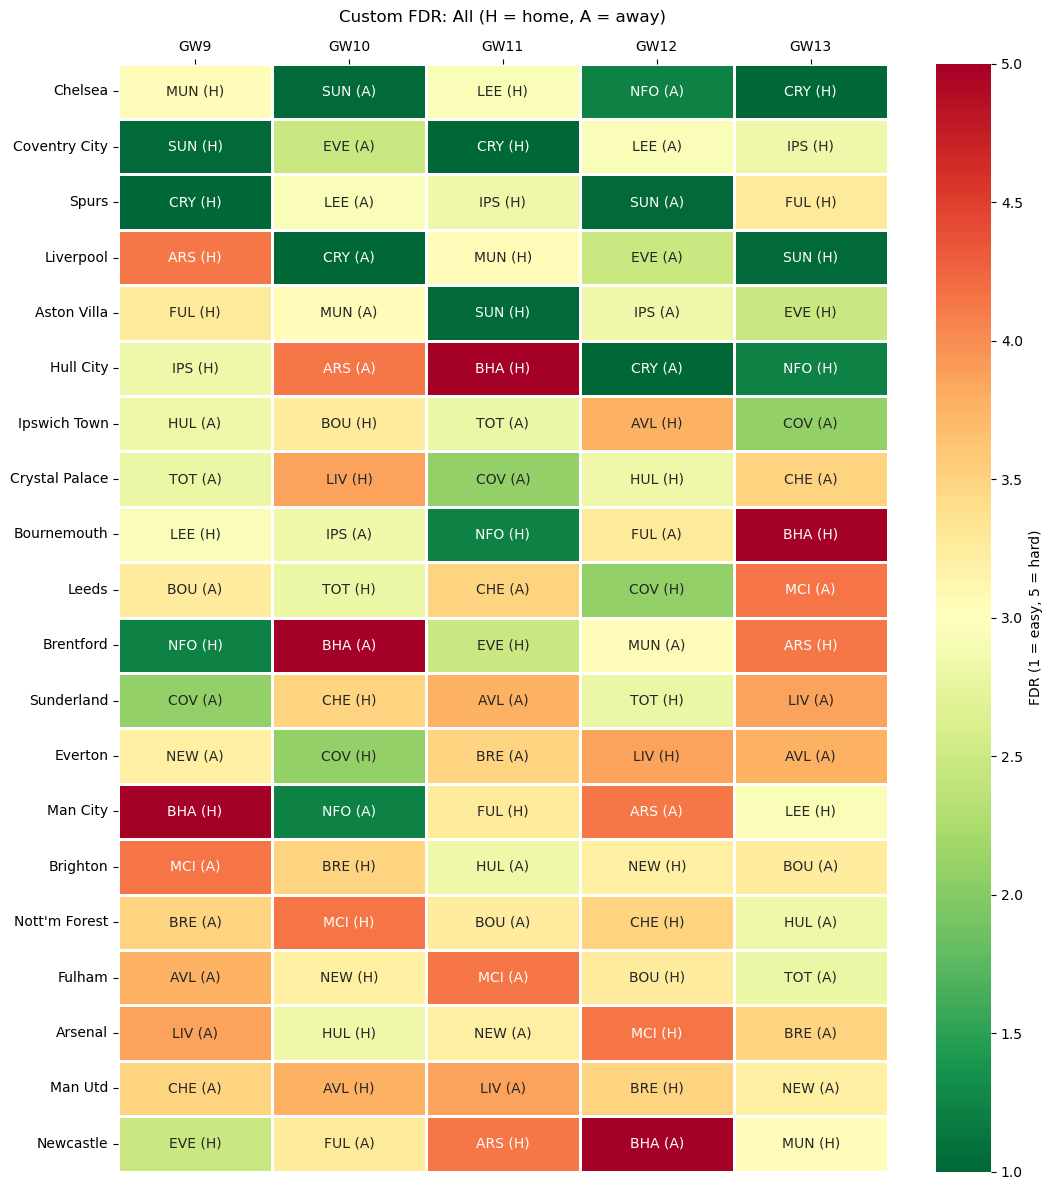

In [179]:
BASE = "https://fantasy.premierleague.com/api"
POS = ["GK", "DEF", "MID", "FWD"]

UPCOMING_GWS = 5      # how many upcoming gameweeks to show
FORM_GWS = 4          # how many recent gameweeks count as "form"
SEASON_WEIGHT = 0.5   # 0.5 = equal weight on season median and recent form

# %% Cell 2: fetch static data (teams, players, fixtures)
static = requests.get(f"{BASE}/bootstrap-static/").json()

# Team id -> full name / short name
teams = {t["id"]: t["name"] for t in static["teams"]}
short = {t["id"]: t["short_name"] for t in static["teams"]}

# Player id -> team and position
players = pd.DataFrame(static["elements"])[["id", "team", "element_type"]]
players["pos"] = players.element_type.map(dict(zip(range(1, 5), POS)))

# Fixtures indexed by fixture id (used to find home/away team)
fixtures = pd.DataFrame(requests.get(f"{BASE}/fixtures/").json())
fixtures = fixtures[["id", "event", "team_h", "team_a"]].set_index("id")

# Read gameweeks from the API instead of hardcoding them
finished = [e["id"] for e in static["events"] if e["finished"]]
upcoming = [e["id"] for e in static["events"] if not e["finished"]][:UPCOMING_GWS]
print("Finished GWs:", finished)
print("Upcoming GWs:", upcoming)

# %% Cell 3: one row per player per match
rows = []
for gw in finished:
    live = requests.get(f"{BASE}/event/{gw}/live/").json()["elements"]
    for el in live:
        # 'explain' has one entry per match, so double gameweeks are handled correctly
        for ex in el["explain"]:
            rows.append((el["id"], gw, ex["fixture"],
                         sum(s["points"] for s in ex["stats"])))
    time.sleep(0.5)  # be gentle with the API

df = (pd.DataFrame(rows, columns=["id", "gw", "fixture", "points"])
        .merge(players, on="id")
        .merge(fixtures[["team_h", "team_a"]], left_on="fixture", right_index=True))

# The opponent is the team that concedes these points
df["opp"] = df.apply(lambda r: r.team_a if r.team == r.team_h else r.team_h, axis=1)
df.head()

# %% Cell 4: weakness (season) and form (recent gameweeks)
match = (df.groupby(["opp", "fixture", "gw", "pos"]).points.sum()
           .unstack("pos").reset_index())
match["All"] = match[POS].sum(axis=1)

cols = POS + ["All"]

# Season weakness: median is robust against one-off blowouts
season = match.groupby("opp")[cols].median()

# Recent form: plain mean over the last FORM_GWS gameweeks
form = match[match.gw > max(finished) - FORM_GWS].groupby("opp")[cols].mean()

# Combined weakness score (higher = concedes more points)
weak = SEASON_WEIGHT * season + (1 - SEASON_WEIGHT) * form

weak.rename(index=teams).sort_values("All", ascending=False).round(1)

# Z-score per position: 0 = league average, +1 = one std dev weaker than average
weak_z = (weak - weak.mean()) / weak.std()

# Continuous 1-5 scale like the official FDR (1 = easiest, 5 = hardest)
weak_fdr = 1 + 4 * (weak.max() - weak) / (weak.max() - weak.min())

weak_fdr.rename(index=teams).sort_values("All").round(1)

# %% Cell 5: upcoming fixtures
fut_rows = []
for f in fixtures[fixtures.event.isin(upcoming)].itertuples():
    fut_rows.append((f.event, f.team_h, f.team_a, True))    # home team's view
    fut_rows.append((f.event, f.team_a, f.team_h, False))   # away team's view

future = pd.DataFrame(fut_rows, columns=["gw", "team", "opp", "home"])

# Cell label, e.g. "SUN (A)" = away at Sunderland
future["label"] = future.apply(
    lambda r: f"{short[r.opp]} ({'H' if r.home else 'A'})", axis=1)

# %% Cell 6: heatmap function
def fdr_heatmap(position="All", scale=None, cmap="RdYlGn_r", filename=None):
    """Default: 1-5 FDR scale. Green = easy opponent (1), red = hard opponent (5)."""
    if scale is None:
        scale = weak_fdr

    future["value"] = future.opp.map(scale[position])

    # Colour = mean per match, so double gameweeks don't look extra green
    value = future.pivot_table(index="team", columns="gw", values="value", aggfunc="mean")

    # Cell text; double gameweeks show both opponents on separate lines
    text = future.groupby(["team", "gw"]).label.agg("\n".join).unstack("gw")

    # Sort teams by the total over the period (lowest sum = easiest run on the 1-5 scale)
    # For z-scores (high = weak opponent) use ascending=False instead
    ascending = cmap.endswith("_r")
    order = future.groupby("team").value.sum().sort_values(ascending=ascending).index
    value = value.reindex(index=order, columns=upcoming)
    text = text.reindex(index=order, columns=upcoming).fillna("-")  # blank gameweeks

    value.index = value.index.map(teams)
    text.index = text.index.map(teams)

    label = "FDR (1 = easy, 5 = hard)" if cmap.endswith("_r") else "Z-score (higher = weaker opponent)"

    fig, ax = plt.subplots(figsize=(1.6 * len(upcoming) + 3, 0.5 * len(value) + 2))
    sns.heatmap(value, annot=text.values, fmt="", cmap=cmap,
                linewidths=1, linecolor="white",
                cbar_kws={"label": label},
                xticklabels=[f"GW{c}" for c in upcoming], yticklabels=True, ax=ax)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.xaxis.tick_top()
    ax.set_title(f"Custom FDR: {position} (H = home, A = away)", pad=30)
    plt.tight_layout()
    if filename:
        plt.savefig(filename, dpi=150)
    return fig

# %% Cell 7: run it (one call per position)
fdr_heatmap("All")
plt.show()

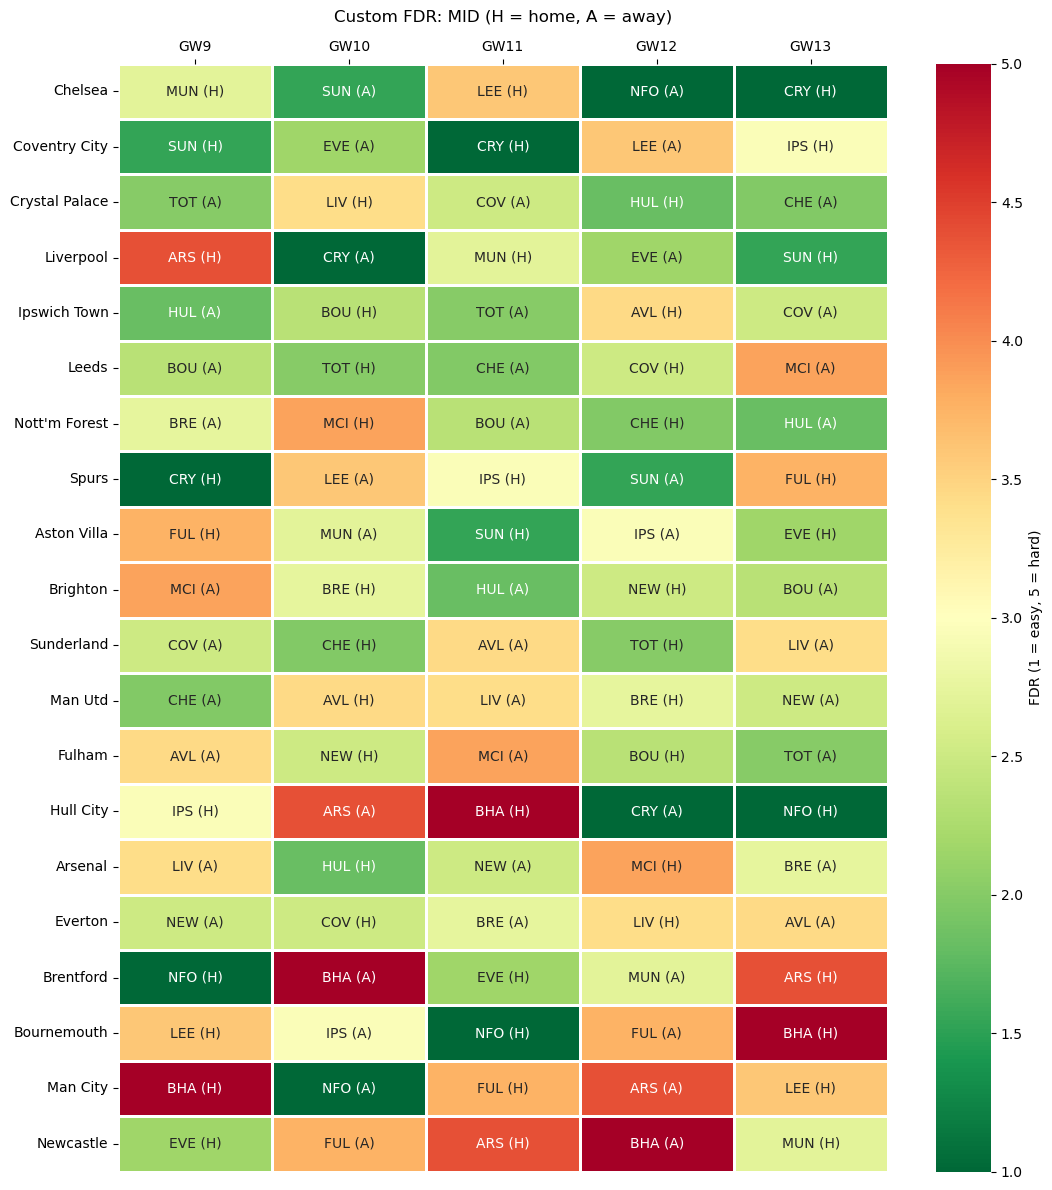

In [180]:
fdr_heatmap("MID")
plt.show()

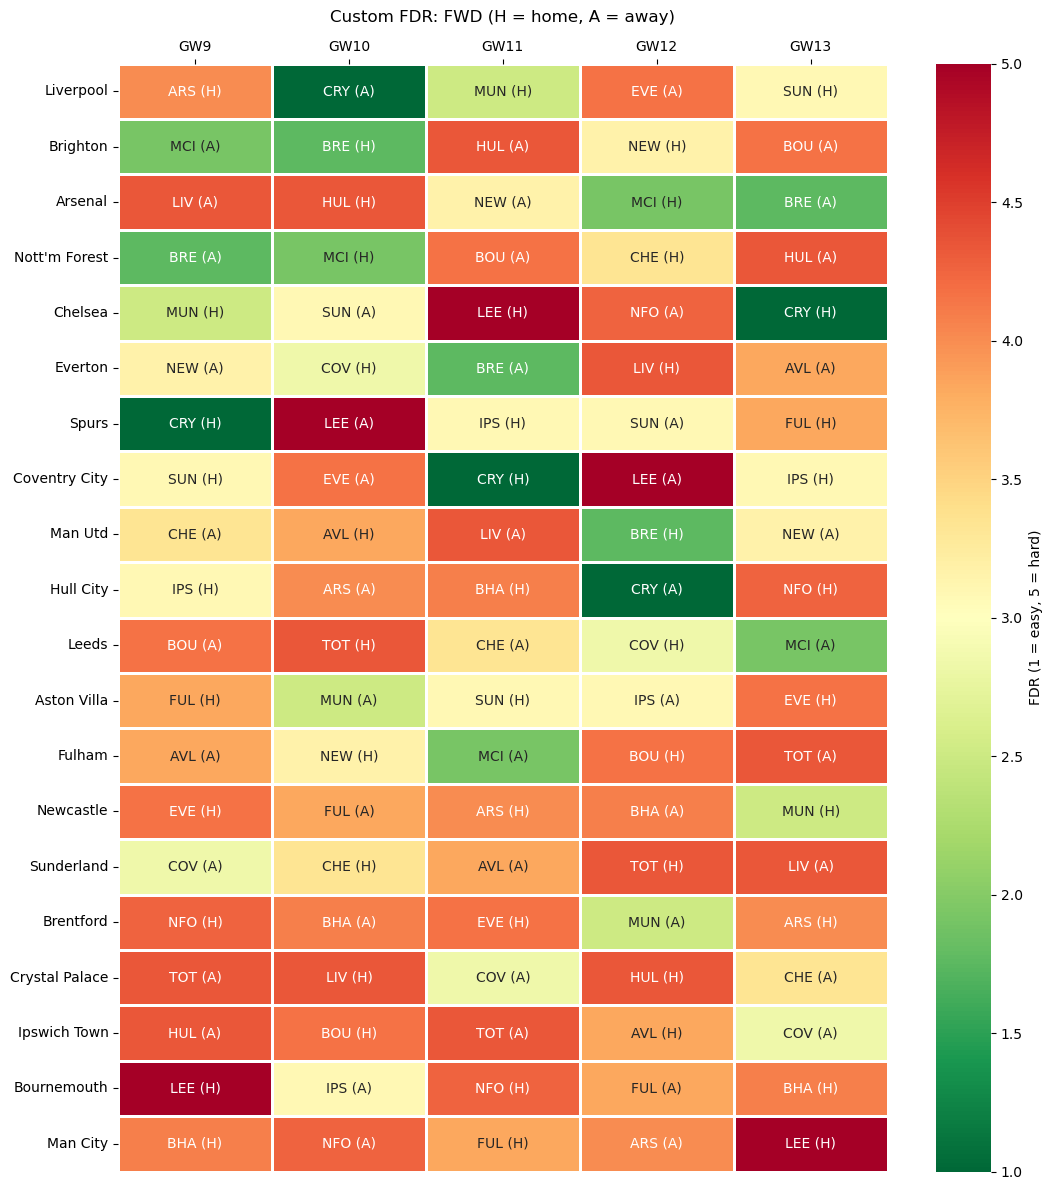

In [181]:
fdr_heatmap("FWD")
plt.show()

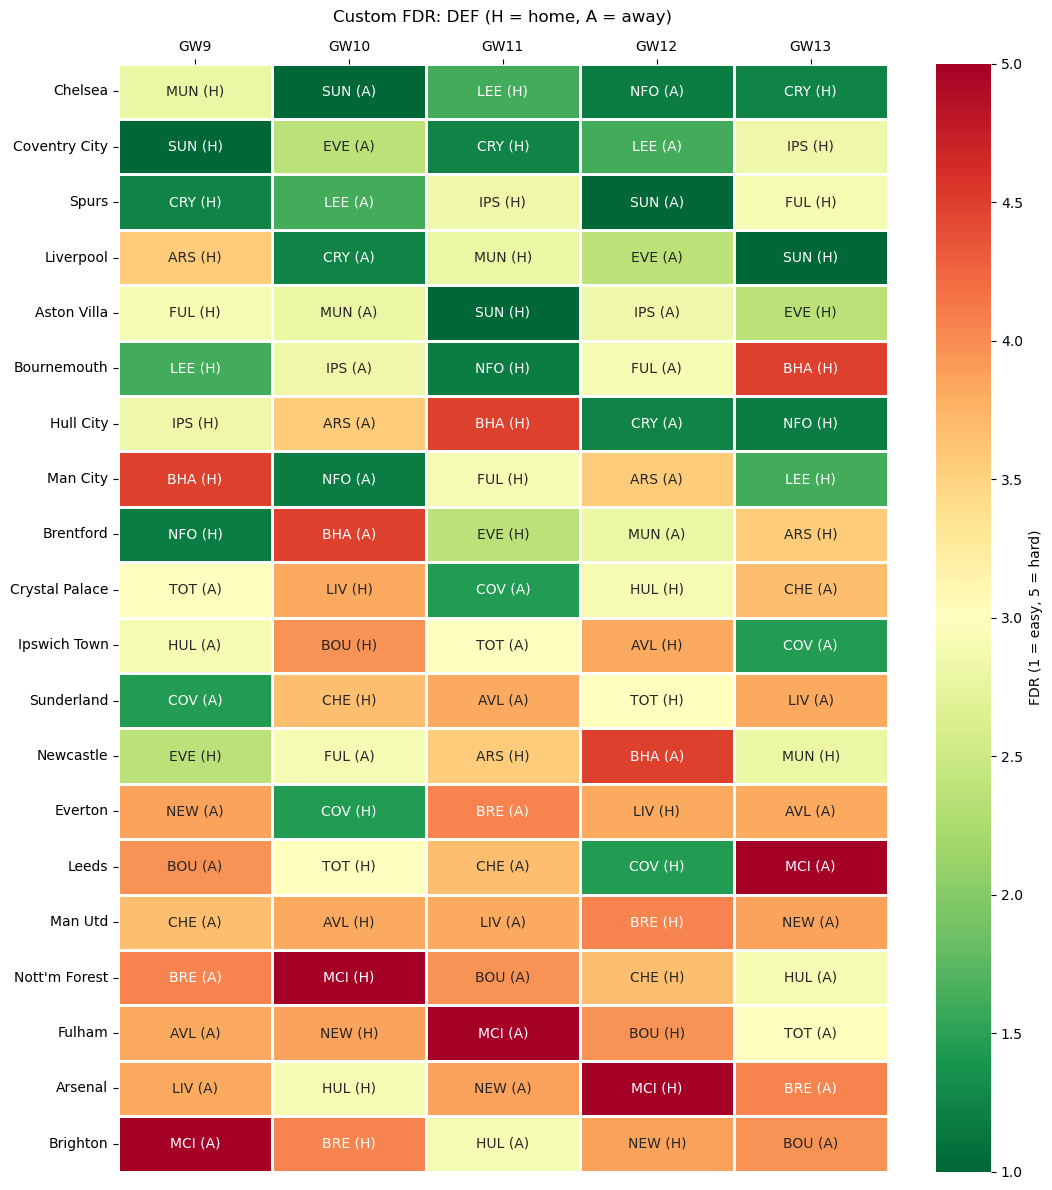

In [182]:
fdr_heatmap("DEF")
plt.show()